## Model Comparison Notebook

### This notebook contains a script that reads the config.json and validation_results.json files from all subfolders in 'runs' folder, to flatten the hyperparameters and the results, separating it by the task (regression vs classification).

Imports 

In [6]:
import os
import json
import pandas as pd

import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

In [7]:
runs_data = []

for root, _, files in os.walk("runs"):
    if "config.json" in files and "validation_metrics.json" in files:
        with open(os.path.join(root, "config.json"), "r") as f:
            config = json.load(f)

        with open(os.path.join(root, "validation_metrics.json"), "r") as f:
            metrics = json.load(f)

        run_info = {**config, **metrics}
        run_info["run_dir"] = os.path.relpath(
            root, start=os.path.dirname("runs")
        )
        runs_data.append(run_info)

# Flatten all nested dictionaries
df_all = pd.json_normalize(runs_data)

# Filter out unnecessary metadata columns dynamically
metadata_prefixes = ("versions.", "preparation.", "split_sha256.")
irrelevant_cols = ["device", "feature_workers", "seed", "targets", "output_dir"]

# Filter out matching prefixes, constant hardware fields, and sample count '.n' columns
clean_cols = [
    col
    for col in df_all.columns
    if not col.startswith(metadata_prefixes)
    and not col.endswith(".n")
    and col not in irrelevant_cols
]

df_clean = df_all[clean_cols]

# Separate into Classification and Regression comparison tables
df_classification = (
    df_clean[df_clean["task"] == "classification"]
    .drop(columns=["task"])
    .set_index("run_dir")
    .dropna(how="all", axis=1)
)

df_regression = (
    df_clean[df_clean["task"] == "regression"]
    .drop(columns=["task"])
    .set_index("run_dir")
    .dropna(how="all", axis=1)
)

print(f"{len(df_classification)} runs of Classification tasks are stored in df_classification.")

print(f"\n{len(df_regression)} runs of Regression tasks are stored in df_regression.")

62 runs of Classification tasks are stored in df_classification.

4 runs of Regression tasks are stored in df_regression.


In [ ]:
df_regression.head()

,data,readout.type,readout.hidden_dim,readout.num_layers,readout.dropout,model.name,model.type,model.featurizers,model.morgan.radius,model.morgan.n_bits,model.morgan.use_counts,model.feature_workers,model.scaling,model.readout_lr,train.epochs,train.batch_size,train.weight_decay,train.grad_clip,macro_ST-RAE,CYP1A2_pIC50_direct_inhibition.MAE,CYP1A2_pIC50_direct_inhibition.R2,CYP1A2_pIC50_direct_inhibition.ST-RAE,CYP2C9_pIC50_direct_inhibition.MAE,CYP2C9_pIC50_direct_inhibition.R2,CYP2C9_pIC50_direct_inhibition.ST-RAE,CYP2D6_pIC50_direct_inhibition.MAE,CYP2D6_pIC50_direct_inhibition.R2,CYP2D6_pIC50_direct_inhibition.ST-RAE,CYP3A4_pIC50_direct_inhibition.MAE,CYP3A4_pIC50_direct_inhibition.R2,CYP3A4_pIC50_direct_inhibition.ST-RAE
run_dir,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
runs/regression/morgan_rdkit_mlp/2026-11-02_14-07-16,data,mlp,512,3,0.1,morgan_rdkit_mlp,features,"[morgan, rdkit]",2,1024,True,4,quantile,0.001,100.0,64.0,0.01,10.0,0.743491,0.748016,0.095772,0.880705,0.515337,0.375077,0.642736,0.658289,0.097163,0.970731,0.590123,0.511188,0.479793
runs/regression/morgan_mlp/2026-11-02_13-42-22,data,mlp,512,3,0.1,morgan_mlp,features,[morgan],2,1024,True,4,quantile,0.001,100.0,64.0,0.01,10.0,0.839105,0.782798,0.052141,0.950417,0.563513,0.270050,0.722004,0.676668,0.087786,1.022534,0.653029,0.430971,0.661464
runs/regression/morgan_mlp/2026-11-02_13-39-16,data,mlp,512,3,0.1,morgan_mlp,features,[morgan],2,1024,True,4,quantile,0.001,100.0,64.0,0.01,10.0,0.840846,0.770051,0.078450,0.927005,0.566302,0.234814,0.753216,0.661355,0.080312,0.984515,0.704512,0.371511,0.698649
runs/regression/morgan_mlp/2026-11-02_13-41-38,data,mlp,512,3,0.1,morgan_mlp,features,[morgan],2,1024,True,4,quantile,0.001,100.0,64.0,0.01,10.0,0.839105,0.782798,0.052141,0.950417,0.563513,0.270050,0.722004,0.676668,0.087786,1.022534,0.653029,0.430971,0.661464


### Here you can swap the dataframe of choice (regression vs classification), and the metric you want to observe

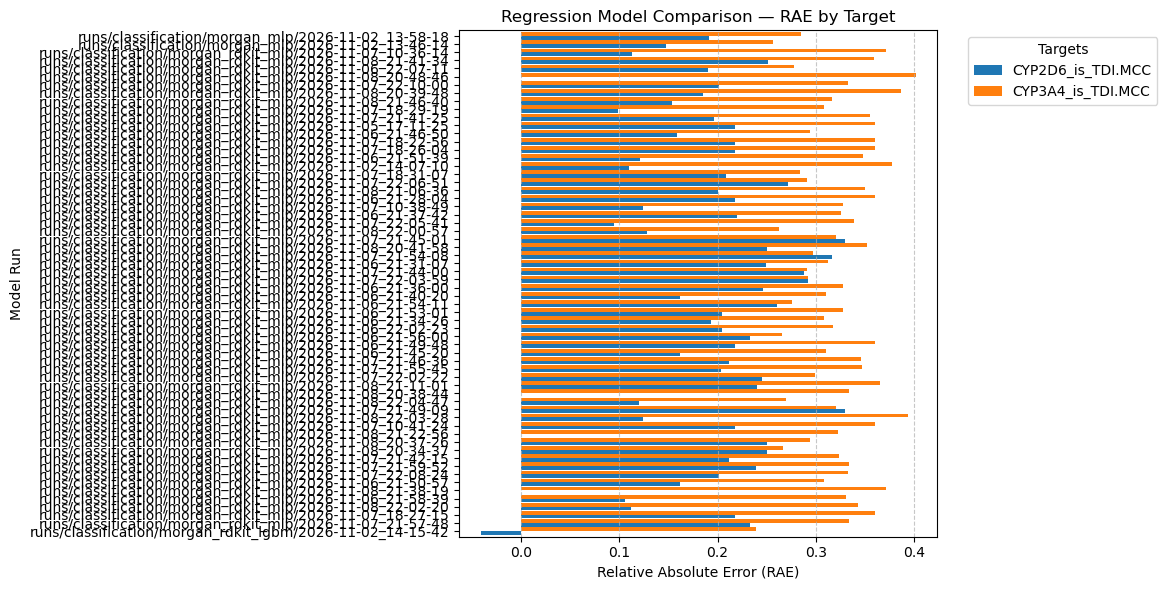

In [11]:
# Select metrics to compare (e.g., RAE for each CYP target)
rae_cols = [col for col in df_classification.columns if col.endswith(".MCC")]

# Plot horizontal bar chart
ax = df_classification[rae_cols].plot(
    kind="barh", figsize=(12, 6), width=0.9
)

plt.title("Regression Model Comparison — RAE by Target")
plt.xlabel("Relative Absolute Error (RAE)")
plt.ylabel("Model Run")
plt.legend(title="Targets", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()